In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score

df = pd.read_csv('weapon_data.csv')



Исходный размер данных: (269, 27)


# 1. Изучаем характеристики целевой переменной

In [ ]:
print(f"Исходный размер данных: {df.shape}")

def visualize_distribution(data, variable):
    fig, ax = plt.subplots(1, 2, figsize=(15, 4))
    sns.histplot(data=data, x=variable, ax=ax[0], kde=True, color='skyblue')
    sns.boxplot(data=data, x=variable, ax=ax[1], color='lightblue')
    ax[0].set_title(f'Гистограмма переменной {variable}')
    ax[1].set_title(f'Ящик с усами переменной {variable}')
    plt.show()

Распределение площади объекта ДО очистки:


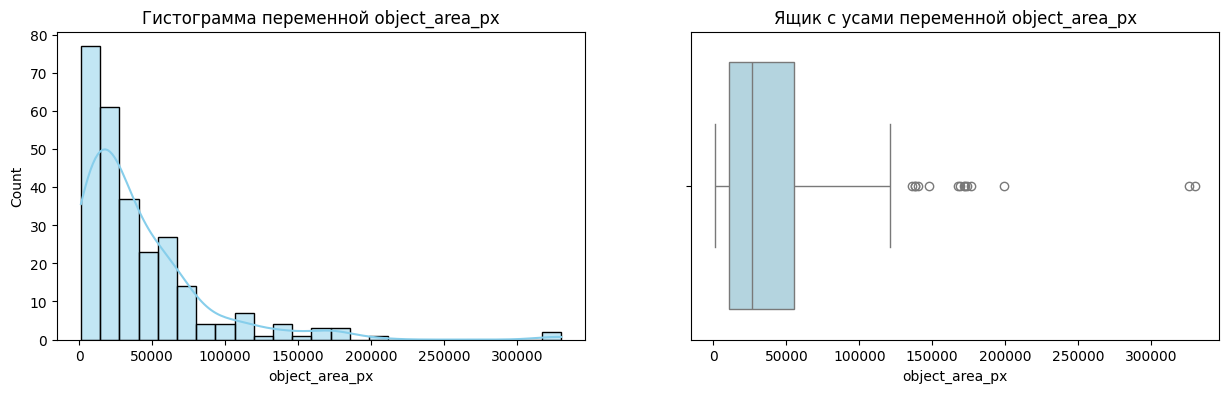

In [7]:
print("Распределение площади объекта ДО очистки:")
visualize_distribution(df, 'object_area_px')

# 2. Удаляем нули и некорректные значения

In [ ]:
df = df[(df['confidence_score'] >= 0) & (df['confidence_score'] <= 1)] # Вероятность должна быть от 0 до 1
df = df[df['aspect_ratio'] > 0]
df = df.dropna(subset=['object_area_px', 'weapon_detected', 'confidence_score'])


# Удаляем выбросы посредством IQR
Q1 = df['object_area_px'].quantile(0.05) # 5 процентиль площади
Q3 = df['object_area_px'].quantile(0.95) # 95 процентиль площади
IQR = Q3 - Q1
lower_bound = max(50, Q1 - 1.5 * IQR) # Выбираем максимальные от нижней границы в 50 пикселей (оружие не может занимать меньше 50 пикселей)
upper_bound = Q3 + 1.5 * IQR

df_clean = df[(df['object_area_px'] >= lower_bound) & (df['object_area_px'] <= upper_bound)]

Размер данных ПОСЛЕ очистки: (267, 27)
Распределение площади объекта ПОСЛЕ очистки:


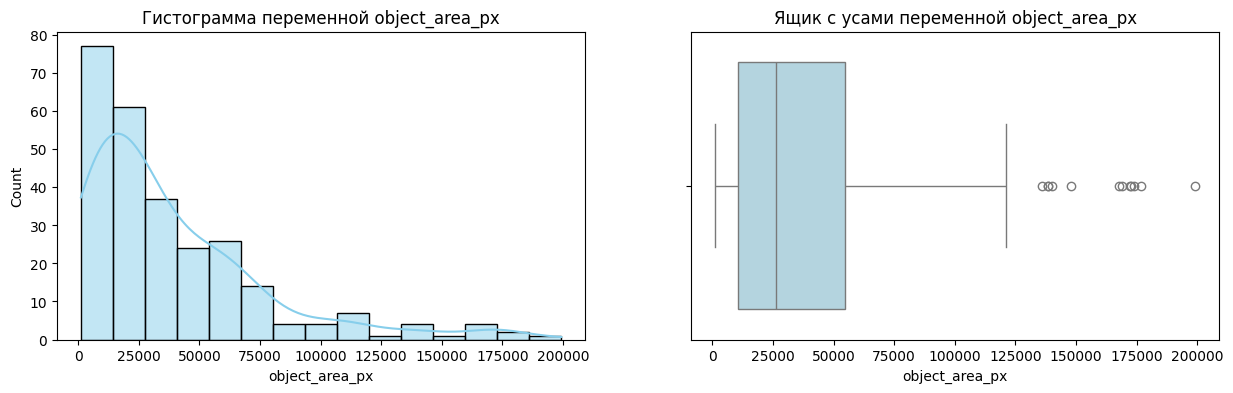

In [8]:
print(f"Размер данных ПОСЛЕ очистки: {df_clean.shape}")
print("Распределение площади объекта ПОСЛЕ очистки:")
visualize_distribution(df_clean, 'object_area_px')

# 3. Разделение на выборки

In [ ]:
from sklearn.model_selection import train_test_split

# Берем все детекции (и оружие, и людей)
df_model = df_clean.copy()

# Кодирование категориальных переменных
df_model['lighting_enc'] = df_model['lighting_condition'].map({'good': 2, 'poor': 1, 'night': 0})
df_model['resolution_enc'] = df_model['resolution_quality'].map({'high': 2, 'medium': 1, 'low': 0})

# Выбираем признаки (X) и целевую переменную (y)
features = ['object_area_px', 'aspect_ratio', 'distance_from_center', 
            'relative_object_size', 'lighting_enc', 'resolution_enc']
X = df_model[features]
y = df_model['confidence_score']

# Разделяем: 70% на обучение, 30% на тест
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

print(f"Размер обучающей выборки: {X_train.shape[0]} строк")
print(f"Размер тестовой выборки: {X_test.shape[0]} строк")
print(f"\nСреднее значение confidence_score в train: {y_train.mean():.4f}")
print(f"Среднее значение confidence_score в test: {y_test.mean():.4f}")

Размер обучающей выборки: 186 строк
Размер тестовой выборки: 81 строк

Среднее значение confidence_score в train: 0.7201
Среднее значение confidence_score в test: 0.6893


# 4 Обучение моделей с разными спецификациями

In [20]:
from sklearn.linear_model import LinearRegression

# Спецификация 1: Все признаки
model_1 = LinearRegression()
model_1.fit(X_train, y_train)

# Спецификация 2: Только геометрические признаки (без контекста)
X_train_2 = X_train[['object_area_px', 'aspect_ratio', 'distance_from_center', 'relative_object_size']]
X_test_2 = X_test[['object_area_px', 'aspect_ratio', 'distance_from_center', 'relative_object_size']]
model_2 = LinearRegression()
model_2.fit(X_train_2, y_train)

# Спецификация 3: Только контекстные признаки (освещение и качество)
X_train_3 = X_train[['lighting_enc', 'resolution_enc']]
X_test_3 = X_test[['lighting_enc', 'resolution_enc']]
model_3 = LinearRegression()
model_3.fit(X_train_3, y_train)

# Спецификация 4: Минимальный набор (размер + позиция)
X_train_4 = X_train[['object_area_px', 'distance_from_center']]
X_test_4 = X_test[['object_area_px', 'distance_from_center']]
model_4 = LinearRegression()
model_4.fit(X_train_4, y_train)

# Спецификация 5: С логарифмической трансформацией площади (нелинейная зависимость)
X_train_5 = X_train.copy()
X_train_5['log_area'] = np.log1p(X_train_5['object_area_px'])
X_train_5 = X_train_5[['log_area', 'distance_from_center', 'lighting_enc', 'resolution_enc']]

X_test_5 = X_test.copy()
X_test_5['log_area'] = np.log1p(X_test_5['object_area_px'])
X_test_5 = X_test_5[['log_area', 'distance_from_center', 'lighting_enc', 'resolution_enc']]

model_5 = LinearRegression()
model_5.fit(X_train_5, y_train)

models = {
    'Модель 1': (model_1, X_train, X_test), # (Все признаки)
    'Модель 2': (model_2, X_train_2, X_test_2), # (Только геометрия)
    'Модель 3': (model_3, X_train_3, X_test_3), # (Только контекст)
    'Модель 4': (model_4, X_train_4, X_test_4), # (Размер + позиция)
    'Модель 5': (model_5, X_train_5, X_test_5), # (Лог + контекст)
}

print("Все 5 моделей обучены!")

Все 5 моделей обучены!


# 5. Предсказания и расчет метрик качества

In [21]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, mean_absolute_percentage_error, r2_score

results = []

for name, (model, X_tr, X_te) in models.items():
    # Делаем предсказания для тестовой выборки
    y_pred = model.predict(X_te)
    
    # Рассчитываем метрики
    mse = mean_squared_error(y_test, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred)
    r2 = r2_score(y_test, y_pred)
    
    results.append({
        'Модель': name,
        'R²': round(r2, 4),
        'MAE': round(mae, 4),
        'RMSE': round(rmse, 4),
        'MAPE': round(mape, 4)
    })
    
    print(f"{name}:")
    print(f"  R² = {r2:.4f}")
    print(f"  MAE = {mae:.4f}")
    print(f"  RMSE = {rmse:.4f}")
    print(f"  MAPE = {mape:.4f}")
    print()

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

Модель 1:
  R² = -0.1062
  MAE = 0.1089
  RMSE = 0.1288
  MAPE = 0.1679

Модель 2:
  R² = -0.0877
  MAE = 0.1075
  RMSE = 0.1277
  MAPE = 0.1663

Модель 3:
  R² = -0.0804
  MAE = 0.1067
  RMSE = 0.1273
  MAPE = 0.1657

Модель 4:
  R² = -0.0886
  MAE = 0.1075
  RMSE = 0.1278
  MAPE = 0.1664

Модель 5:
  R² = -0.1326
  MAE = 0.1102
  RMSE = 0.1303
  MAPE = 0.1699

  Модель      R²    MAE   RMSE   MAPE
Модель 1 -0.1062 0.1089 0.1288 0.1679
Модель 2 -0.0877 0.1075 0.1277 0.1663
Модель 3 -0.0804 0.1067 0.1273 0.1657
Модель 4 -0.0886 0.1075 0.1278 0.1664
Модель 5 -0.1326 0.1102 0.1303 0.1699


# 7: Выбор лучшей модели

In [22]:
# Выбираем лучшую модель по R²
best_idx = results_df['R²'].idxmax()
best_model_name = results_df.loc[best_idx, 'Модель']
best_r2 = results_df.loc[best_idx, 'R²']

print(f"Лучшая модель: {best_model_name}")
print(f"R² на тестовой выборке: {best_r2:.4f}")

# Получаем лучшую модель и её тестовые данные
best_model, _, X_test_best = models[best_model_name]

Лучшая модель: Модель 3
R² на тестовой выборке: -0.0804


# 8: Визуализация предсказаний лучшей модели

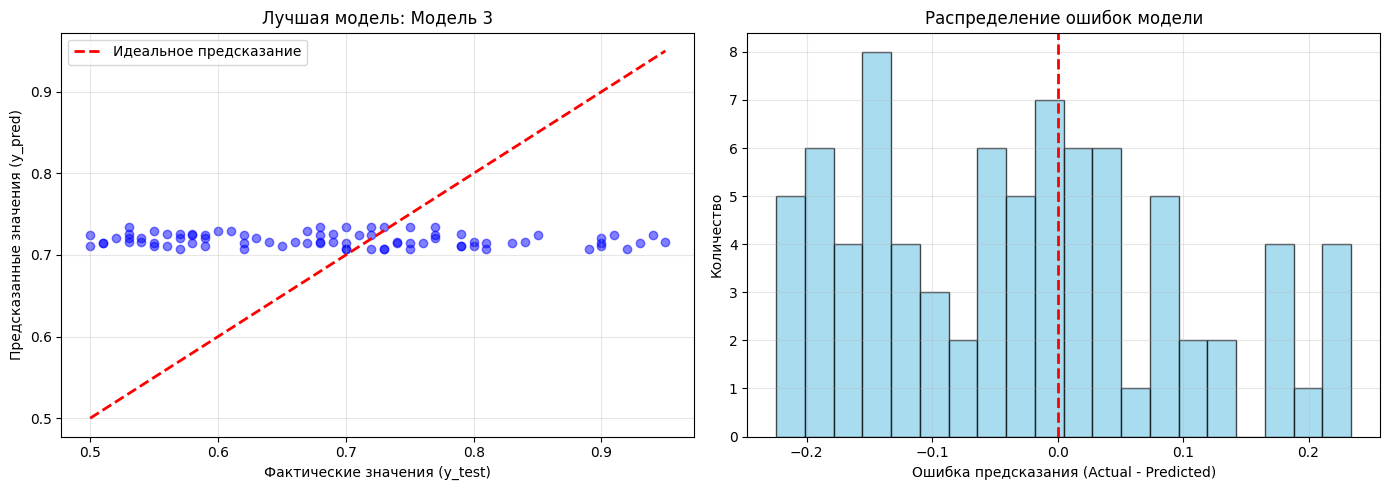

In [23]:
# Делаем предсказания лучшей модели
y_pred_best = best_model.predict(X_test_best)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: Фактические vs Предсказанные значения
axes[0].scatter(y_test, y_pred_best, alpha=0.5, color='blue')
min_val = min(y_test.min(), y_pred_best.min())
max_val = max(y_test.max(), y_pred_best.max())
axes[0].plot([min_val, max_val], [min_val, max_val], 'r--', linewidth=2, label='Идеальное предсказание')
axes[0].set_xlabel('Фактические значения (y_test)')
axes[0].set_ylabel('Предсказанные значения (y_pred)')
axes[0].set_title(f'Лучшая модель: {best_model_name}')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# График 2: Распределение ошибок
errors = y_test - y_pred_best
axes[1].hist(errors, bins=20, edgecolor='black', color='skyblue', alpha=0.7)
axes[1].set_xlabel('Ошибка предсказания (Actual - Predicted)')
axes[1].set_ylabel('Количество')
axes[1].set_title('Распределение ошибок модели')
axes[1].axvline(0, color='red', linestyle='--', linewidth=2)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Линейная регрессия показала неудовлетворительные результаты для задачи предсказания confidence_score в системе детекции оружия. Отрицательный R² (-0.0804) указывает на то, что модель не способна уловить зависимость между признаками и целевой переменной.
Возможные причины: Слабая линейная зависимость, Недостаточный объем данных, Возможная нелинейность связи